In [ ]:
%pip install -q -U gdown

In [ ]:

import os
import zipfile
import gdown

ID_ARQUIVO = "1sfxXot_oiW_u-WYdoTqgooLpJiJ1UClJ"
CAMINHO_ZIP = "nx_network_data (1).zip"

# Verifica se o ZIP já existe e é válido
if not (
    os.path.isfile(CAMINHO_ZIP)
    and zipfile.is_zipfile(CAMINHO_ZIP)
):

    print("Baixando arquivo do Google Drive...")

    # Baixa sem autenticação do usuário
    gdown.download(
        id=ID_ARQUIVO,
        output=CAMINHO_ZIP,
        quiet=False
    )

# Verifica o arquivo baixado
if os.path.isfile(CAMINHO_ZIP) and zipfile.is_zipfile(CAMINHO_ZIP):
    with zipfile.ZipFile(CAMINHO_ZIP, "r") as zip_ref:
        print("ZIP carregado com sucesso!")
        print(f"Total de arquivos: {len(zip_ref.namelist())}")
else:
    raise RuntimeError(
        "Não foi possível baixar um ZIP válido. "
        "Verifique as permissões do Google Drive."
    )


ZIP carregado com sucesso!
Total de arquivos: 11276


  2000/11257 arquivos lidos...
  4000/11257 arquivos lidos...
  6000/11257 arquivos lidos...
  8000/11257 arquivos lidos...
  10000/11257 arquivos lidos...
Grafo 1 carregado com sucesso!
Total de cascatas: 11257 | arquivos ignorados: 0
source      label
gossipcop   fake     3684
            real     6945
politifact  fake      351
            real      277

--- FALSAS x VERDADEIRAS (medianas por fonte) ---
                  cascatas  tamanho_mediano  profundidade_mediana  ramificacao_mediana  t10_mediano_h  t10_calculavel
source     label                                                                                                     
gossipcop  fake       3684             30.0                   2.0                  3.0          11.03            2960
           real       6945             73.0                   2.0                  2.0           0.36            6845
politifact fake        351            239.0                   5.0                 20.0           7.97             336
 

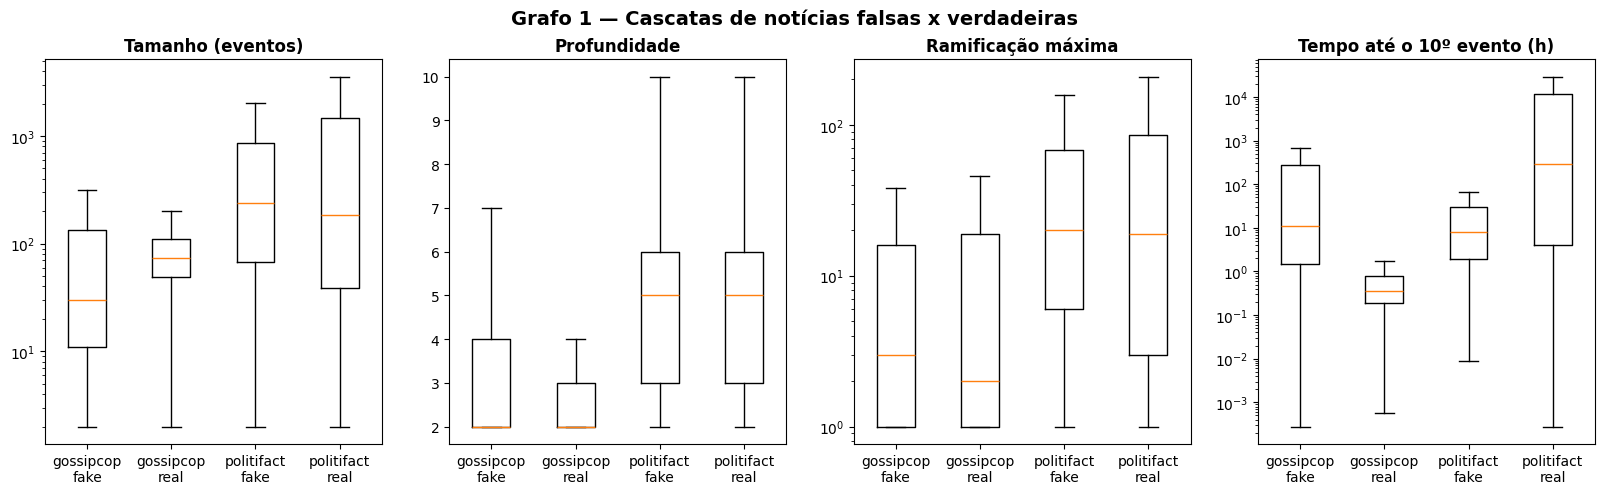

Gráficos salvos como 'grafo1_comparacao.png'!
Gerando ilustração baseada nos dados do Grafo 1...
Cascata selecionada: gossipcop-6362183032
Publicações: 1044 | Retuítes: 689 | Respostas: 262
Cascata 'gossipcop-6362183032': 1996 nós e 1995 arestas (sem recorte).
Tipos desenhados: {1: 1, 2: 1044, 4: 262, 3: 689}


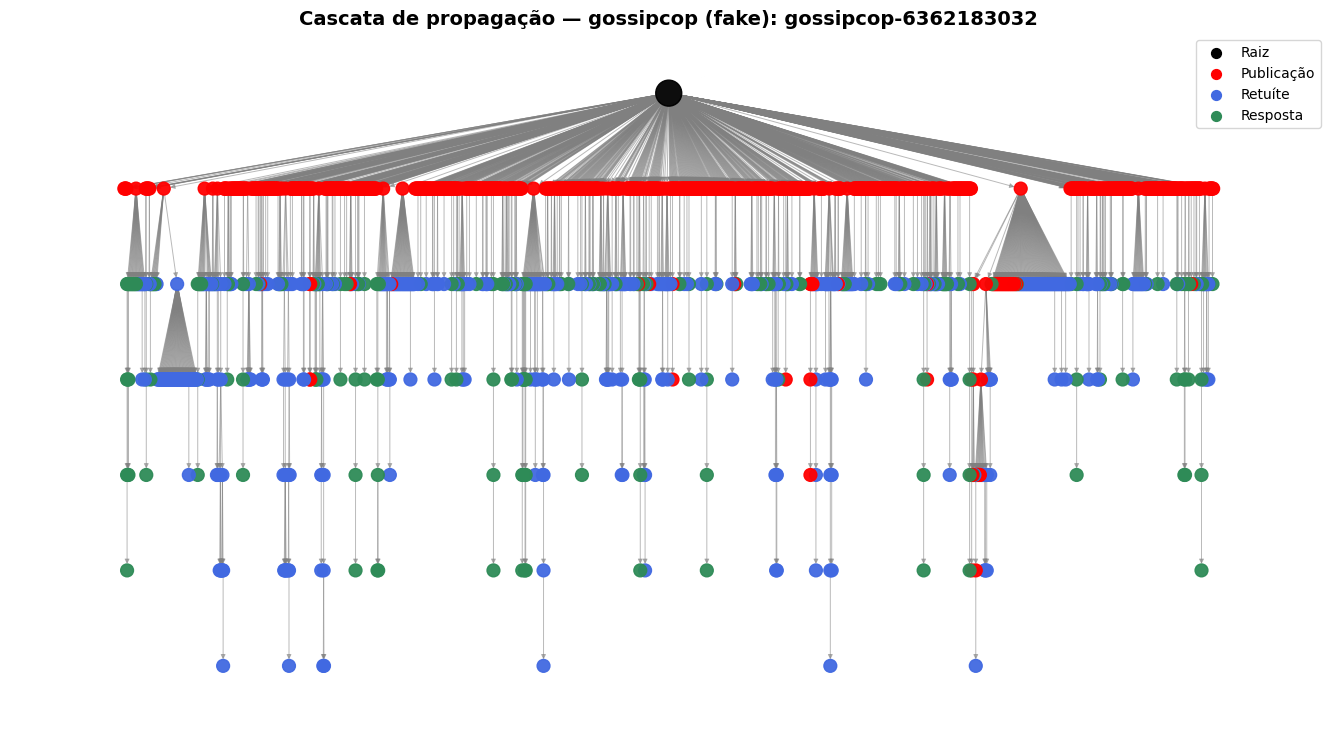

Ilustração salva como 'grafo1_ilustracao.png'!


In [ ]:
#Grafo 1
import json
import re
import zipfile
from collections import deque, Counter

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

#CONFIGURAÇÃO
CAMINHO_ZIP = "nx_network_data (1).zip"
UNIDADE_TEMPO_S = 1.0
FONTE_ILUSTRACAO = "gossipcop"       # gossipcop ou politifact
CLASSE_ILUSTRACAO = "fake"          # fake ou real
MAX_NOS_ILUSTRACAO = 2000           # limite incluindo a raiz
MIN_NOS_ILUSTRACAO = 50             # mínimo incluindo a raiz

TIPO_RAIZ, TIPO_POST, TIPO_RT, TIPO_RESP = 1, 2, 3, 4


def construir_arvore(dados_json):
    # Percurso em largura: cada objeto JSON vira um nó distinto.
    G = nx.DiGraph()
    raiz_id = 0
    G.add_node(raiz_id, tipo=dados_json.get("type", TIPO_RAIZ),
               tempo=dados_json.get("time"), usuario=dados_json.get("user"),
               tweet_id=dados_json.get("tweet_id"), profundidade=0)
    contador = 1
    fila = deque([(dados_json, raiz_id)])
    while fila:
        no_json, pai_id = fila.popleft()
        for filho in no_json.get("children", []) or []:
            filho_id = contador
            contador += 1
            G.add_node(filho_id, tipo=filho.get("type"), tempo=filho.get("time"),
                       usuario=filho.get("user"), tweet_id=filho.get("tweet_id"),
                       profundidade=G.nodes[pai_id]["profundidade"] + 1)
            G.add_edge(pai_id, filho_id)
            fila.append((filho, filho_id))
    return G, raiz_id


def _tempo_valido(t):
    try:
        return float(t) if t is not None and float(t) > 0 else None
    except (TypeError, ValueError):
        return None


def calcular_metricas(G, raiz_id, unidade_tempo_s=1.0):
    # A raiz artificial não conta como evento.
    reais = [n for n in G.nodes if n != raiz_id]
    tipos = [G.nodes[n]["tipo"] for n in reais]
    tamanho = len(reais)
    profundidade = max((G.nodes[n]["profundidade"] for n in reais), default=0)
    ramificacao = max((G.out_degree(n) for n in reais), default=0)
    folhas = sum(1 for n in reais if G.out_degree(n) == 0)
    tempos = sorted(t for t in (_tempo_valido(G.nodes[n]["tempo"]) for n in reais)
                    if t is not None)
    t10_h = (tempos[9] - tempos[0]) * unidade_tempo_s / 3600 if len(tempos) >= 10 else None
    duracao_h = (tempos[-1] - tempos[0]) * unidade_tempo_s / 3600 if len(tempos) >= 2 else None
    usuarios = {G.nodes[n]["usuario"] for n in reais if G.nodes[n]["usuario"] is not None}
    return {
        "tamanho": tamanho,
        "n_posts": tipos.count(TIPO_POST),
        "n_retuites": tipos.count(TIPO_RT),
        "n_respostas": tipos.count(TIPO_RESP),
        "n_usuarios_unicos": len(usuarios),
        "profundidade": profundidade,
        "ramificacao_max": ramificacao,
        "prop_folhas": folhas / tamanho if tamanho else None,
        "t10_horas": t10_h,
        "duracao_horas": duracao_h,
    }


def identificar_fonte_e_classe(caminho):
    c = caminho.lower()
    fonte = "gossipcop" if "gossipcop" in c else "politifact" if "politifact" in c else None
    classe = "fake" if re.search(r"(^|[/_\\-])fake", c) else "real" if re.search(r"(^|[/_\\-])real", c) else None
    return fonte, classe


def carregar_cascatas(caminho_zip, unidade_tempo_s=1.0):
    linhas, ignorados = [], 0
    with zipfile.ZipFile(caminho_zip) as z:
        nomes = [n for n in z.namelist()
                 if n.lower().endswith(".json") and not n.startswith("__MACOSX/")
                 and not n.rsplit("/", 1)[-1].startswith("._")]
        for i, nome in enumerate(nomes, 1):
            fonte, classe = identificar_fonte_e_classe(nome)
            if fonte is None or classe is None:
                ignorados += 1
                continue
            try:
                dados = json.loads(z.read(nome))
                G, raiz = construir_arvore(dados)
            except (json.JSONDecodeError, UnicodeDecodeError, TypeError, AttributeError):
                ignorados += 1
                continue
            linha = {"source": fonte, "label": classe,
                     "filename": nome.rsplit("/", 1)[-1].removesuffix(".json"),
                     "caminho_zip": nome}
            linha.update(calcular_metricas(G, raiz, unidade_tempo_s))
            linhas.append(linha)
            if i % 2000 == 0:
                print(f"  {i}/{len(nomes)} arquivos lidos...")
    df = pd.DataFrame(linhas)
    print("Grafo 1 carregado com sucesso!")
    print(f"Total de cascatas: {len(df)} | arquivos ignorados: {ignorados}")
    if not df.empty:
        print(df.groupby(["source", "label"]).size().to_string())
    return df


def comparar_falsas_x_verdadeiras(df):
    tab = (df.groupby(["source", "label"])
             .agg(cascatas=("tamanho", "size"),
                  tamanho_mediano=("tamanho", "median"),
                  profundidade_mediana=("profundidade", "median"),
                  ramificacao_mediana=("ramificacao_max", "median"),
                  t10_mediano_h=("t10_horas", "median"),
                  t10_calculavel=("t10_horas", lambda s: s.notna().sum()))
             .round(2))
    print("\n--- FALSAS x VERDADEIRAS (medianas por fonte) ---")
    print(tab.to_string())
    return tab


def gerar_graficos_comparativos(df, nome_arquivo_saida="grafo1_comparacao.png"):
    metricas = [("tamanho", "Tamanho (eventos)", True),
                ("profundidade", "Profundidade", False),
                ("ramificacao_max", "Ramificação máxima", True),
                ("t10_horas", "Tempo até o 10º evento (h)", True)]
    fig, eixos = plt.subplots(1, 4, figsize=(20, 5))
    for ax, (col, titulo, log) in zip(eixos, metricas):
        grupos, rotulos = [], []
        for (fonte, classe), g in df.groupby(["source", "label"]):
            v = g[col].dropna()
            if log:
                v = v[v > 0]  # Escala logarítmica não admite zero.
            if len(v):
                grupos.append(v)
                rotulos.append(f"{fonte}\n{classe}")
        if grupos:
            ax.boxplot(grupos, tick_labels=rotulos, showfliers=False)
            if log:
                ax.set_yscale("log")
        else:
            ax.text(0.5, 0.5, "Sem dados válidos", ha="center", va="center",
                    transform=ax.transAxes)
        ax.set_title(titulo, fontweight="bold")
    fig.suptitle("Grafo 1 — Cascatas de notícias falsas x verdadeiras",
                 fontsize=14, fontweight="bold")
    plt.savefig(nome_arquivo_saida, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"Gráficos salvos como '{nome_arquivo_saida}'!")


def selecionar_cascata_ilustracao(df, fonte="gossipcop", classe="fake",
                                  max_nos=150, min_nos=50):
    # O DataFrame registra eventos sem a raiz, por isso somamos 1.
    sel = df[(df["source"] == fonte) & (df["label"] == classe)]
    sel = sel[(sel["n_posts"] > 0) & (sel["n_retuites"] > 0) &
              (sel["n_respostas"] > 0) & (sel["tamanho"] + 1 <= max_nos) &
              (sel["tamanho"] + 1 >= min_nos)]
    if sel.empty:
        print(f"Nenhuma cascata de {fonte}/{classe} com os quatro tipos "
              f"e entre {min_nos} e {max_nos} nós.")
        return None
    linha = sel.sort_values("tamanho", ascending=False).iloc[0]
    print(f"Cascata selecionada: {linha['filename']}")
    print(f"Publicações: {linha['n_posts']} | Retuítes: {linha['n_retuites']} | "
          f"Respostas: {linha['n_respostas']}")
    return linha


def layout_arvore_hierarquico(G, raiz):
    # Posiciona as folhas da esquerda para a direita e cada pai no centro
    # dos seus filhos. Implementação iterativa para evitar limite de recursão.
    ordem = list(nx.dfs_preorder_nodes(G, raiz))
    pos = {}
    proximo_x = 0
    for no in reversed(ordem):
        filhos = list(G.successors(no))
        if filhos:
            x = (pos[filhos[0]][0] + pos[filhos[-1]][0]) / 2
        else:
            x = proximo_x
            proximo_x += 1
        pos[no] = (x, -G.nodes[no]["profundidade"])
    return pos


def gerar_ilustracao_grafo1(caminho_zip, df, fonte="gossipcop", classe="fake",
                            max_nos=150, nome_arquivo_saida="grafo1_ilustracao.png"):
    print("Gerando ilustração baseada nos dados do Grafo 1...")
    linha = selecionar_cascata_ilustracao(df, fonte, classe, max_nos)
    if linha is None:
        return
    with zipfile.ZipFile(caminho_zip) as z:
        G, raiz = construir_arvore(json.loads(z.read(linha["caminho_zip"])))

    # A cascata escolhida já cabe no limite: desenhar todos os seus nós.
    print(f"Cascata '{linha['filename']}': {G.number_of_nodes()} nós e "
          f"{G.number_of_edges()} arestas (sem recorte).")
    print("Tipos desenhados:", dict(Counter(nx.get_node_attributes(G, "tipo").values())))
    pos = layout_arvore_hierarquico(G, raiz)
    cor = {TIPO_RAIZ: "black", TIPO_POST: "red",
           TIPO_RT: "royalblue", TIPO_RESP: "seagreen"}
    cores_nos = [cor.get(G.nodes[n]["tipo"], "gray") for n in G.nodes]
    tamanhos_nos = [350 if n == raiz else 85 for n in G.nodes]

    fig, ax = plt.subplots(figsize=(17, 9))
    nx.draw_networkx_edges(G, pos, ax=ax, width=0.7, alpha=0.55,
                           edge_color="gray", arrows=True, arrowsize=7,
                           node_size=tamanhos_nos)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=tamanhos_nos,
                           node_color=cores_nos, alpha=0.95)
    for rotulo, c in [("Raiz", "black"), ("Publicação", "red"), ("Retuíte", "royalblue"), ("Resposta", "seagreen")]:
        ax.scatter([], [], c=c, label=rotulo, s=50)
    ax.legend(loc="upper right")
    ax.set_title(f"Cascata de propagação — {fonte} ({classe}): {linha['filename']}",
                 fontsize=14, fontweight="bold")
    ax.axis("off")
    fig.savefig(nome_arquivo_saida, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Ilustração salva como '{nome_arquivo_saida}'!")


df_cascatas = carregar_cascatas(CAMINHO_ZIP, UNIDADE_TEMPO_S)
if not df_cascatas.empty:
    df_cascatas.drop(columns="caminho_zip").to_csv("metricas_cascatas.csv", index=False)
    tabela_comparativa = comparar_falsas_x_verdadeiras(df_cascatas)
    gerar_graficos_comparativos(df_cascatas)
    gerar_ilustracao_grafo1(CAMINHO_ZIP, df_cascatas,
                            FONTE_ILUSTRACAO, CLASSE_ILUSTRACAO,
                            MAX_NOS_ILUSTRACAO)


In [ ]:
# Grafo 2

import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt

def normalizar_usuario(usuario):
    # Mantém os IDs como texto para comparar corretamente nos dois grafos.
    if usuario is None:
        return None
    usuario = str(usuario).strip()
    if not usuario or usuario.lower() in ("none", "nan", "null"):
        return None
    return usuario


def carregar_grafo(caminho_zip, df=None):

    #Constrói o Grafo 2 lendo o ZIP de JSONs usado no Grafo 1.

    G2 = nx.DiGraph()
    noticias = {}
    ignorados = 0

    with zipfile.ZipFile(caminho_zip) as z:
        if df is not None:
            # Reutiliza as cascatas identificadas e classificadas no Grafo 1.
            entradas = df[["caminho_zip", "source", "label"]].to_dict("records")
        else:
            entradas = []
            for nome in z.namelist():
                if (not nome.lower().endswith(".json") or
                        nome.startswith("__MACOSX/") or
                        nome.rsplit("/", 1)[-1].startswith("._")):
                    continue
                fonte, classe = identificar_fonte_e_classe(nome)
                if fonte is not None and classe is not None:
                    entradas.append({"caminho_zip": nome,
                                     "source": fonte, "label": classe})

        for i, linha in enumerate(entradas, 1):
            try:
                dados = json.loads(z.read(linha["caminho_zip"]))
                G, raiz = construir_arvore(dados)
            except (json.JSONDecodeError, UnicodeDecodeError, KeyError,
                    TypeError, AttributeError):
                ignorados += 1
                continue

            # Guardar a notícia separadamente dos usuários evita contar
            # publicações/retuítes/respostas como notícias diferentes.
            usuarios_noticia = set()
            autores_noticia = set()
            usuarios_por_no = {}
            arestas_noticia = []
            for no, atributos in G.nodes(data=True):
                if no == raiz:  # A raiz é artificial, não é um usuário.
                    continue
                usuario = normalizar_usuario(atributos.get("usuario"))
                usuarios_por_no[no] = usuario
                if usuario is not None:
                    usuarios_noticia.add(usuario)
                    G2.add_node(usuario)
                if usuario is not None and atributos.get("tipo") == TIPO_POST:
                    autores_noticia.add(usuario)

            noticias[linha["caminho_zip"]] = {
                "source": linha["source"],
                "label": linha["label"],
                "usuarios": usuarios_noticia,
                "autores": autores_noticia,
                "arestas": arestas_noticia
            }

            for pai, filho in G.edges():
                usuario_pai = usuarios_por_no.get(pai)
                usuario_filho = usuarios_por_no.get(filho)
                if (usuario_pai is None or usuario_filho is None or
                        usuario_pai == usuario_filho):
                    continue

                arestas_noticia.append((usuario_pai, usuario_filho))

                if not G2.has_edge(usuario_pai, usuario_filho):
                    G2.add_edge(usuario_pai, usuario_filho,
                                Weight=0, Weight_fake=0, Weight_real=0)

                G2[usuario_pai][usuario_filho]["Weight"] += 1
                G2[usuario_pai][usuario_filho][
                    "Weight_fake" if linha["label"] == "fake" else "Weight_real"
                ] += 1

            if i % 2000 == 0:
                print(f"  {i}/{len(entradas)} cascatas processadas no Grafo 2...")

    # A correspondência notícia -> usuários permite contar as notícias
    # remanescentes depois de excluir vértices, sem reabrir o ZIP.
    G2.graph["noticias"] = noticias
    print("Grafo 2 carregado com sucesso!")
    print(f"Total de usuários (nós): {G2.number_of_nodes()}")
    print(f"Total de conexões diretas (arestas): {G2.number_of_edges()}")
    print(f"Total de notícias (cascatas) processadas: {len(noticias)}")
    print(f"Arquivos ignorados: {ignorados}")
    return G2


def simular_banimento(G2, usuarios_banidos):

    usuarios_banidos = {
        normalizar_usuario(u) for u in usuarios_banidos
    }
    usuarios_banidos.discard(None)

    G2_filtrado = nx.DiGraph()

    noticias_originais = G2.graph["noticias"]
    noticias_restantes = {}
    noticias_removidas = set()
    noticias_afetadas = set()

    # Analisa cada notícia individualmente
    for caminho, noticia in noticias_originais.items():

        autores = noticia["autores"]
        usuarios = noticia["usuarios"]

        # Se um usuário banido publicou a notícia,
        # a publicação original é removida.
        if autores.intersection(usuarios_banidos):
            noticias_removidas.add(caminho)
            continue

        # Se o usuário apenas participou da disseminação,
        # a notícia permanece, mas sua participação é eliminada.
        if usuarios.intersection(usuarios_banidos):
            noticias_afetadas.add(caminho)

        # Remove os usuários banidos da lista de participantes
        usuarios_restantes = usuarios - usuarios_banidos

        noticia_filtrada = noticia.copy()
        noticia_filtrada["usuarios"] = usuarios_restantes

        noticias_restantes[caminho] = noticia_filtrada

        # Reconstrói as conexões apenas com usuários não banidos
        for origem, destino in noticia["arestas"]:

            if origem in usuarios_banidos or destino in usuarios_banidos:
                continue

            if not G2_filtrado.has_edge(origem, destino):
                G2_filtrado.add_edge(
                    origem, destino,
                    Weight=0,
                    Weight_fake=0,
                    Weight_real=0
                )

            G2_filtrado[origem][destino]["Weight"] += 1

            atributo = (
                "Weight_fake"
                if noticia["label"] == "fake"
                else "Weight_real"
            )

            G2_filtrado[origem][destino][atributo] += 1

        # Preserva os usuários restantes, inclusive os isolados
        G2_filtrado.add_nodes_from(usuarios_restantes)

    # Guarda somente as notícias que não foram removidas
    G2_filtrado.graph["noticias"] = noticias_restantes

    print("\n--- SIMULAÇÃO DE BANIMENTO ---")
    print(f"Usuários banidos: {len(usuarios_banidos)}")
    print(f"Notícias removidas: {len(noticias_removidas)}")
    print(f"Notícias afetadas, mas mantidas: {len(noticias_afetadas)}")
    print(f"Notícias restantes: {len(noticias_restantes)}")
    print(f"Conexões restantes: {G2_filtrado.number_of_edges()}")

    return G2_filtrado, noticias_removidas, noticias_afetadas


def calcular_maiores_disseminadores_de_fake_news(G2,top_n=5):

  lista_de_forcas_de_saida = dict(G2.out_degree(weight='Weight_fake'))

  #Ordenar usuarios com base na foça de saída

  usuarios_ord = sorted(
        [(usuario, forca) for usuario, forca in lista_de_forcas_de_saida.items()
         if forca > 0],
        key=lambda x: x[1], reverse=True
    )

  print(f"\n--- TOP {top_n} MAIORES DISSEMINADORES (Força de Saída) ---")
  for i, (usuario, forca) in enumerate(usuarios_ord[:top_n], 1):
      print(f"{i}. Usuário ID: {usuario} | Força de Saída em interações de notícias falsas: {forca}")

  return usuarios_ord

grafo2 = carregar_grafo(CAMINHO_ZIP,
                        df=df_cascatas if not df_cascatas.empty else None)
top_usuarios = calcular_maiores_disseminadores_de_fake_news(grafo2, top_n=5)


  2000/11257 cascatas processadas no Grafo 2...
  4000/11257 cascatas processadas no Grafo 2...
  6000/11257 cascatas processadas no Grafo 2...
  8000/11257 cascatas processadas no Grafo 2...
  10000/11257 cascatas processadas no Grafo 2...
Grafo 2 carregado com sucesso!
Total de usuários (nós): 1123909
Total de conexões diretas (arestas): 1005247
Total de notícias (cascatas) processadas: 11257
Arquivos ignorados: 0

--- TOP 5 MAIORES DISSEMINADORES (Força de Saída) ---
1. Usuário ID: 5885428749 | Força de Saída em interações de notícias falsas: 6360
2. Usuário ID: 2293031070 | Força de Saída em interações de notícias falsas: 5074
3. Usuário ID: 8525916237 | Força de Saída em interações de notícias falsas: 4929
4. Usuário ID: 9844199270 | Força de Saída em interações de notícias falsas: 4851
5. Usuário ID: 9995201997 | Força de Saída em interações de notícias falsas: 4798


In [ ]:
#Função Remover cascatas de publicações geradas pelos maiores disseminadores

def remover_cascatas_por_usuario(caminho_zip, df, usuario_alvo_id):

    if isinstance(usuario_alvo_id, (list, tuple, set)):
        usuarios_alvo = {normalizar_usuario(u) for u in usuario_alvo_id}
    else:
        usuarios_alvo = {normalizar_usuario(usuario_alvo_id)}

    usuarios_alvo.discard(None)

    print(f"\n[Filtro] Removendo cascatas publicadas pelo usuário ID: {usuario_alvo_id}...")

    arquivos_para_remover = set()

    # 1. Varre os arquivos ZIP para identificar quais cascatas pertencem ao usuário alvo
    with zipfile.ZipFile(caminho_zip) as z:
        for _, linha in df.iterrows():
            try:
                dados = json.loads(z.read(linha["caminho_zip"]))
                G, raiz = construir_arvore(dados)

                # Identifica nós de publicação (TIPO_POST = 2)
                posts_reais = [n for n in G.nodes if G.nodes[n].get("tipo") == TIPO_POST]

                # Verifica se algum dos posts da árvore pertence ao ID do usuário procurado
                pertence_ao_usuario = any(
                    normalizar_usuario(G.nodes[n].get("usuario")) in usuarios_alvo
                    for n in posts_reais
                )

                if pertence_ao_usuario:
                    arquivos_para_remover.add(linha["caminho_zip"])

            except (json.JSONDecodeError, KeyError, TypeError):
                continue

    print(f"Total de cascatas encontradas e removidas para o usuário {usuario_alvo_id}: {len(arquivos_para_remover)}")

    # 2. Cria um novo DataFrame excluindo as cascatas desse usuário
    df_filtrado = df[~df["caminho_zip"].isin(arquivos_para_remover)].copy()

    print(f"Novo total de cascatas na base: {len(df_filtrado)}")

    # 3. Recalcula as estatísticas e gráficos comparativos com a base limpa
    print("\n--- RECALCULANDO ESTATÍSTICAS APÓS A REMOÇÃO ---")
    comparar_falsas_x_verdadeiras(df_filtrado)
    gerar_graficos_comparativos(df_filtrado, nome_arquivo_saida="grafo1_comparacao_pos_remocao.png")

    return df_filtrado





--- SIMULAÇÃO DE BANIMENTO ---
Usuários banidos: 1
Notícias removidas: 423
Notícias afetadas, mas mantidas: 2
Notícias restantes: 10834
Conexões restantes: 920169

--- SIMULAÇÃO DE BANIMENTO ---
Usuários banidos: 2
Notícias removidas: 2599
Notícias afetadas, mas mantidas: 2
Notícias restantes: 8658
Conexões restantes: 811157

--- SIMULAÇÃO DE BANIMENTO ---
Usuários banidos: 3
Notícias removidas: 4659
Notícias afetadas, mas mantidas: 23
Notícias restantes: 6598
Conexões restantes: 727234

--- SIMULAÇÃO DE BANIMENTO ---
Usuários banidos: 4
Notícias removidas: 4707
Notícias afetadas, mas mantidas: 23
Notícias restantes: 6550
Conexões restantes: 709323

--- SIMULAÇÃO DE BANIMENTO ---
Usuários banidos: 5
Notícias removidas: 4807
Notícias afetadas, mas mantidas: 23
Notícias restantes: 6450
Conexões restantes: 693242

===== RESULTADOS DA REMOÇÃO PROGRESSIVA =====


,Propagadores removidos,Fake restantes,Real restantes,Fake removidas,Real removidas,Notícias removidas,Notícias afetadas,Notícias não afetadas,Redução fake (%),Redução real (%),Usuários restantes,Arestas restantes
0,0,4035,7222,0,0,0,0,11257,0.000000,0.000000,1123909,1005247
1,1,3834,7000,201,222,423,2,10832,4.981413,3.073941,1044596,920169
2,2,1667,6991,2368,231,2599,2,8656,58.686493,3.198560,907300,811157
3,3,1635,4963,2400,2259,4659,23,6575,59.479554,31.279424,831848,727234
4,4,1608,4942,2427,2280,4707,23,6527,60.148699,31.570202,813466,709323
5,5,1590,4860,2445,2362,4807,23,6427,60.594796,32.705622,797423,693242


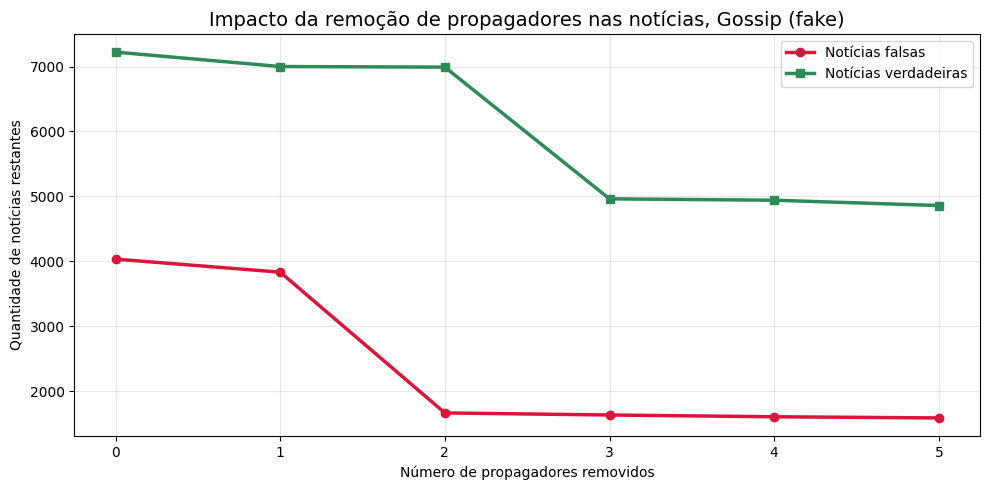

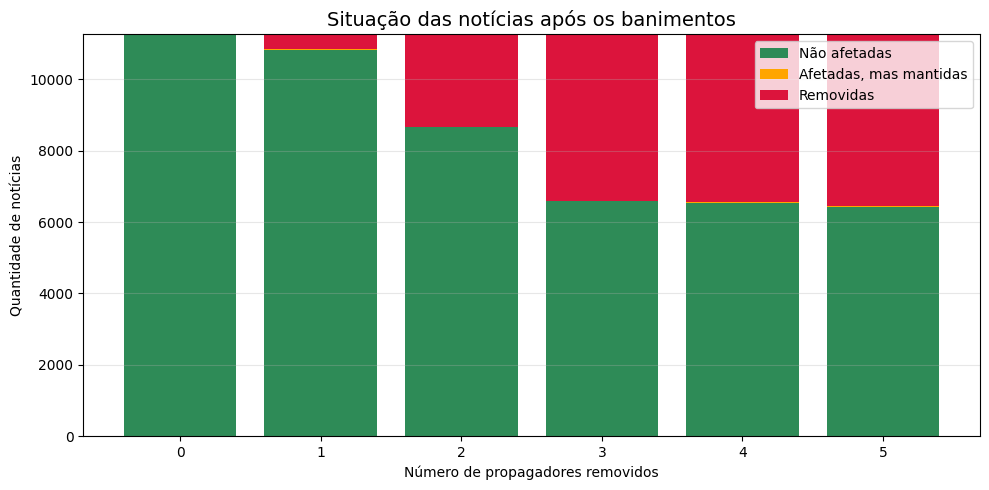

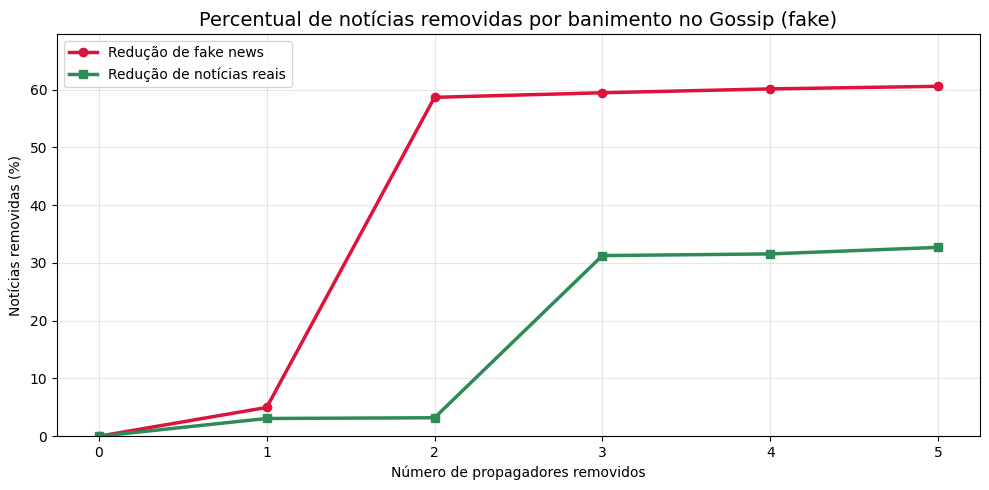

In [ ]:

import copy
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# ANÁLISE DA REMOÇÃO PROGRESSIVA DOS MAIORES PROPAGADORES


MAX_PROPAGADORES = 5

def analisar_remocao_progressiva(grafo2, top_usuarios, max_propagadores=20):

    noticias_originais = grafo2.graph.get("noticias", {})
    ids_originais = set(noticias_originais)

    if not noticias_originais or not top_usuarios:
        print("Não há notícias ou propagadores disponíveis.")
        return pd.DataFrame()

    # Seleciona os maiores propagadores
    usuarios_ordenados = [
        usuario for usuario, forca in top_usuarios[:max_propagadores]
    ]

    total_fake = sum(
        str(n.get("label", "")).lower() == "fake"
        for n in noticias_originais.values()
    )

    total_real = sum(
        str(n.get("label", "")).lower() == "real"
        for n in noticias_originais.values()
    )

    total_noticias = len(noticias_originais)

    resultados = []

    # Simula a remoção de 0, 1, 2, ..., N usuários
    for k in range(len(usuarios_ordenados) + 1):

        if k == 0:
            removidas = set()
            afetadas = set()
            G_filtrado = grafo2
        else:
            usuarios_remover = usuarios_ordenados[:k]

            # Cada simulação começa do grafo original
            # deepcopy evita alterações nos metadados originais
            G_filtrado, noticias_removidas, noticias_afetadas = (
                simular_banimento(
                    copy.deepcopy(grafo2),
                    usuarios_remover
                )
            )

            removidas = set(noticias_removidas) & ids_originais
            afetadas = set(noticias_afetadas) & ids_originais

            # Se a simulação retirou notícias dos metadados,
            # utiliza essa diferença para identificar remoções
            ids_apos = set(
                G_filtrado.graph.get("noticias", {}).keys()
            )

            if len(ids_apos) < len(ids_originais):
                removidas = ids_originais - ids_apos

        # Notícias afetadas que não foram excluídas
        afetadas -= removidas

        fake_removidas = sum(
            str(noticias_originais[id]["label"]).lower() == "fake"
            for id in removidas
        )

        real_removidas = sum(
            str(noticias_originais[id]["label"]).lower() == "real"
            for id in removidas
        )

        fake_restantes = total_fake - fake_removidas
        real_restantes = total_real - real_removidas

        resultados.append({
            "Propagadores removidos": k,
            "Fake restantes": fake_restantes,
            "Real restantes": real_restantes,
            "Fake removidas": fake_removidas,
            "Real removidas": real_removidas,
            "Notícias removidas": len(removidas),
            "Notícias afetadas": len(afetadas),
            "Notícias não afetadas": (
                total_noticias - len(removidas) - len(afetadas)
            ),
            "Redução fake (%)": (
                100 * fake_removidas / total_fake
                if total_fake else 0
            ),
            "Redução real (%)": (
                100 * real_removidas / total_real
                if total_real else 0
            ),
            "Usuários restantes": G_filtrado.number_of_nodes(),
            "Arestas restantes": G_filtrado.number_of_edges()
        })

    df_impacto = pd.DataFrame(resultados)
    x = df_impacto["Propagadores removidos"]

    print("\n===== RESULTADOS DA REMOÇÃO PROGRESSIVA =====")
    display(df_impacto)


    # GRÁFICO 1 - NOTÍCIAS RESTANTES


    fig, ax = plt.subplots(figsize=(10, 5))

    ax.plot(
        x, df_impacto["Fake restantes"],
        marker="o", linewidth=2.5,
        color="crimson", label="Notícias falsas"
    )

    ax.plot(
        x, df_impacto["Real restantes"],
        marker="s", linewidth=2.5,
        color="seagreen", label="Notícias verdadeiras"
    )

    ax.set_title(
        "Impacto da remoção de propagadores nas notícias, Gossip (fake)",
        fontsize=14
    )
    ax.set_xlabel("Número de propagadores removidos")
    ax.set_ylabel("Quantidade de notícias restantes")
    ax.set_xticks(x)
    ax.grid(True, alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.savefig("impacto_noticias_restantes.png", dpi=200)
    plt.show()

    # GRÁFICO 2 - SITUAÇÃO DAS NOTÍCIAS

    fig, ax = plt.subplots(figsize=(10, 5))

    nao_afetadas = df_impacto["Notícias não afetadas"]
    afetadas = df_impacto["Notícias afetadas"]
    removidas = df_impacto["Notícias removidas"]

    ax.bar(
        x, nao_afetadas,
        color="seagreen", label="Não afetadas"
    )

    ax.bar(
        x, afetadas,
        bottom=nao_afetadas,
        color="orange", label="Afetadas, mas mantidas"
    )

    ax.bar(
        x, removidas,
        bottom=nao_afetadas + afetadas,
        color="crimson", label="Removidas"
    )

    ax.set_title(
        "Situação das notícias após os banimentos",
        fontsize=14
    )
    ax.set_xlabel("Número de propagadores removidos")
    ax.set_ylabel("Quantidade de notícias")
    ax.set_xticks(x)
    ax.legend()
    ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.savefig("situacao_noticias.png", dpi=200)
    plt.show()

    # GRÁFICO 3 - REDUÇÃO PERCENTUAL

    fig, ax = plt.subplots(figsize=(10, 5))

    ax.plot(
        x, df_impacto["Redução fake (%)"],
        marker="o", linewidth=2.5,
        color="crimson", label="Redução de fake news"
    )

    ax.plot(
        x, df_impacto["Redução real (%)"],
        marker="s", linewidth=2.5,
        color="seagreen", label="Redução de notícias reais"
    )

    ax.set_title(
        "Percentual de notícias removidas por banimento no Gossip (fake)",
        fontsize=14
    )
    ax.set_xlabel("Número de propagadores removidos")
    ax.set_ylabel("Notícias removidas (%)")
    ax.set_xticks(x)
    ax.set_ylim(0, max(
        5,
        df_impacto["Redução fake (%)"].max() * 1.15,
        df_impacto["Redução real (%)"].max() * 1.15
    ))
    ax.legend()
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig("reducao_percentual_noticias.png", dpi=200)
    plt.show()

    # Salva os dados para análises posteriores
    df_impacto.to_csv(
        "analise_remocao_propagadores.csv",
        index=False
    )

    return df_impacto


# EXECUÇÃO


df_impacto = analisar_remocao_progressiva(
    grafo2,
    top_usuarios,
    max_propagadores=MAX_PROPAGADORES
)


Gerando ilustração baseada nos dados do Grafo 2...
Subgrafo gerado com 56 nós e 50 arestas.


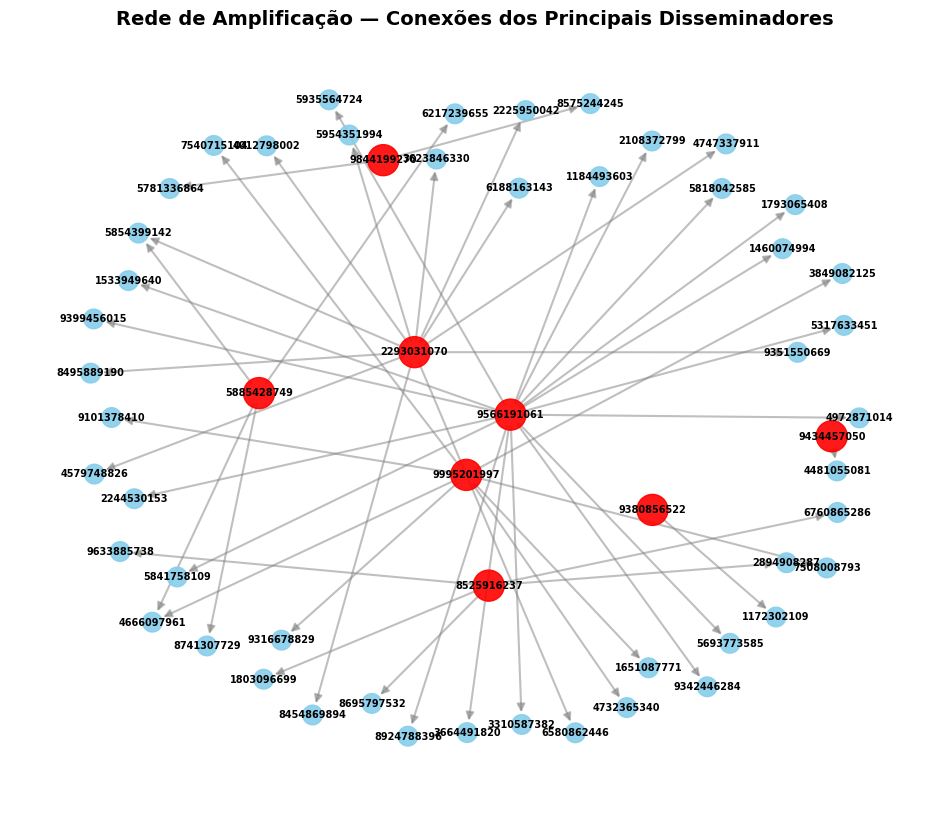

Ilustração salva como 'grafo2_antes_remocao.png'!


In [ ]:

# Grafo 2 — Representação visual

import networkx as nx
import matplotlib.pyplot as plt


def gerar_ilustracao_grafo2(G2, top_usuarios, top_n=10, nome_arquivo_saida="grafo2_ilustracao.png",
                            tipo_peso="Weight_fake"):

    print("Gerando ilustração baseada nos dados do Grafo 2...")

    # Pega os IDs dos principais disseminadores presentes no grafo
    top_usuarios_ids = {
        normalizar_usuario(usuario)
        for usuario, forca in top_usuarios[:top_n]
        if normalizar_usuario(usuario) in G2
    }

    # Seleciona as arestas cuja origem está no Top N
    arestas = []

    for usuario in top_usuarios_ids:
        for origem, destino, atributos in G2.out_edges(usuario, data=True):
            peso = atributos.get(tipo_peso, 0)

            if peso > 0:
                arestas.append((origem, destino, peso))

    # Seleciona as 50 conexões mais fortes
    arestas = sorted(
        arestas, key=lambda x: x[2], reverse=True
    )[:50]

    # Cria o subgrafo direcionado
    G_sub = nx.DiGraph()

    for origem, destino, peso in arestas:
        G_sub.add_edge(origem, destino, Weight=peso)

    print(f"Subgrafo gerado com {G_sub.number_of_nodes()} nós e {G_sub.number_of_edges()} arestas.")

    if G_sub.number_of_nodes() == 0:
        print("Nenhuma conexão encontrada para ilustrar.")
        return G_sub

    plt.figure(figsize=(12, 10))
    pos = nx.spring_layout(G_sub, seed=42, k=0.3)

    # Destaca os maiores disseminadores
    cores_nos = [
        "red" if node in top_usuarios_ids else "skyblue"
        for node in G_sub.nodes()
    ]

    tamanhos_nos = [
        500 if node in top_usuarios_ids else 200
        for node in G_sub.nodes()
    ]

    nx.draw_networkx_nodes(
        G_sub, pos,
        node_size=tamanhos_nos,
        node_color=cores_nos,
        alpha=0.9
    )

    nx.draw_networkx_edges(
        G_sub, pos,
        width=1.5,
        alpha=0.5,
        edge_color="gray",
        arrows=True,
        arrowsize=12
    )

    nx.draw_networkx_labels(
        G_sub, pos,
        font_size=7,
        font_weight="bold"
    )

    plt.title(
        "Rede de Amplificação — Conexões dos Principais Disseminadores",
        fontsize=14,
        fontweight="bold"
    )

    plt.axis("off")
    plt.savefig(nome_arquivo_saida, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"Ilustração salva como '{nome_arquivo_saida}'!")

    return G_sub

# Antes da remoção
subgrafo_antes = gerar_ilustracao_grafo2(
    grafo2,
    top_usuarios,
    top_n=15,
    nome_arquivo_saida="grafo2_antes_remocao.png"
)

